In [14]:
from typing import TYPE_CHECKING
if TYPE_CHECKING:
    from icecream import ic  # noqa: F401

import sys

sys.path.append("..")

import numpy as np
import utils.debug  # noqa: F401

from utils.harmonic import (
    get_harmonic_oscillation,
    get_single_rect_oscillation,
)
from utils.plotting import show_subplots, show_multi_plot, show_plot
from utils.sampling import get_linspace
from utils.fourier import get_fourier_transform
from utils.convolution import (
    get_convolution,
    get_convolution_product,
    get_convolution_series,
)

# 1 Вычисление интеграла свертки

В данной практике выполняется вычисление интеграла свертки и визуализируются промежуточные вычисления.

## 1.1 Вычисление интеграла свертки аналитическим способом

Для временных функций $s_1(t)$ и $s_2(t)$ задайте временные параметры и выполните по шагам вычисление интеграла свертки задавая пределы интегрирования.

## 1.2 Вычисление интеграла свертки численным интегрированием

Сформируйте функцию $s_1(t)$ как функцию времени $t$ (прямоугольный импульс длительности 1 сек).
Сделайте замену переменной $t$ на $\tau$ и изобразите график функции $s_1(-\tau)$.
Изобразите график функции $s_1(t - \tau)$ для значений $t = -1, 0, 2$.
Вычислите произведение функций $s_2(\tau)s_1(t - \tau)$ для значений $t = -1, 0, 2$ в интервале $-5 \le \tau \le 5$.
Вычислите интеграл $\int_{-5}^{5} s_2(\tau)s_1(t - \tau)d\tau$ для значения $t = 0.2$.
Вычислите интеграл $\int_{-5}^{5} s_2(\tau)s_1(t - \tau)d\tau$ для $t$ в интервале $(-1, 2)$. Изобразите результат как функцию времени $t$.

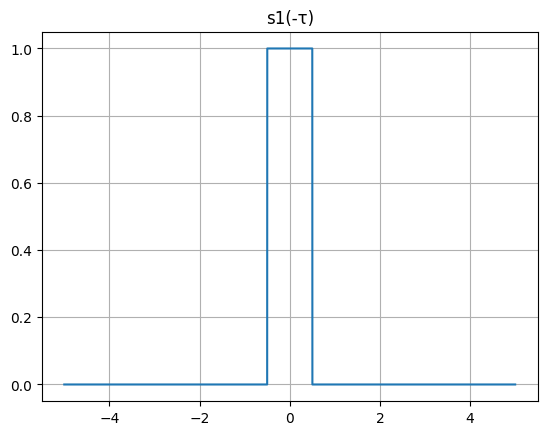

In [15]:
TAU_START = -5
TAU_STOP = 5
TAU_FS = 20000
T_SAMPLES = (-1, 0, 2)
T_INTEGRAL = 0.2

tau = get_linspace(start=TAU_START, stop=TAU_STOP, fs=TAU_FS)

s1 = get_single_rect_oscillation(a=1, tau=1)
s2 = get_single_rect_oscillation(a=1, tau=1)

show_plot(t=tau, func_val=s1(-tau), title="s1(-τ)")

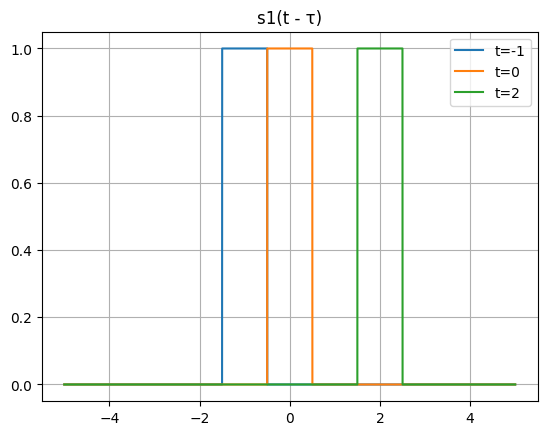

In [16]:
show_multi_plot(
    t=tau,
    func_vals=[s1(t - tau) for t in T_SAMPLES],
    labels=[f"t={t}" for t in T_SAMPLES],
    title="s1(t - τ)",
)

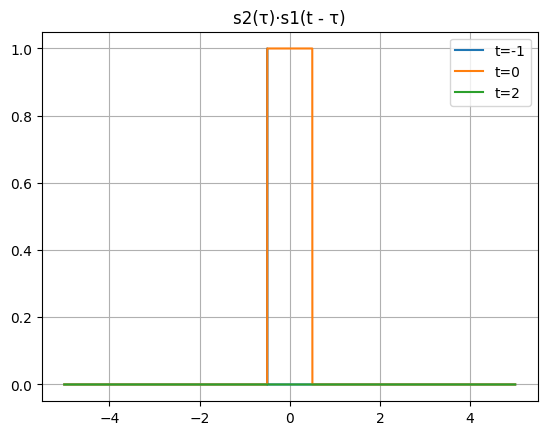

In [17]:
# products = [s2(tau) * s1(t - tau) for t in T_SAMPLES]
products = [get_convolution_product(s1, s2, tau, t) for t in T_SAMPLES]

show_multi_plot(
    t=tau,
    func_vals=products,
    labels=[f"t={t}" for t in T_SAMPLES],
    title="s2(τ)·s1(t - τ)",
)

In [18]:
ic(T_INTEGRAL, get_convolution(s1, s2, tau, T_INTEGRAL)); # интеграл s2(tau) * s1(t - tau) 

ic| T_INTEGRAL: 0.2
    get_convolution(s1, s2, tau, T_INTEGRAL): np.float64(0.8004999999995563)


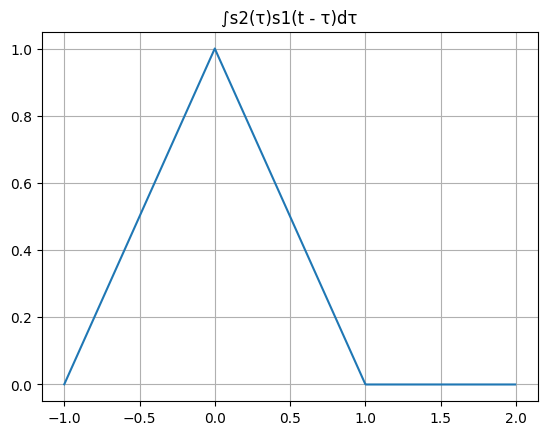

In [19]:
t_values = get_linspace(start=-1, stop=2, fs=600)
convolution = get_convolution_series(s1, s2, tau, t_values)

show_plot(t=t_values, func_val=convolution, title="∫s2(τ)s1(t - τ)dτ")